# Feedback-free starbursts (FFB) with `halogal`

This notebook introduces the feedback-free starburst models in `halogal`. Every UV and stellar-mass class has an `_FFB` variant: `UVHMRModel_FFB`, `SHMRModel_FFB`, `UVHODModel_FFB` and `MstarHODModel_FFB`. Each one adds two parameters, `ffb_delta` and `eps_max_ffb`, and otherwise behaves exactly like its standard parent. It assumes you have seen the UV tutorial (`basic_usage.ipynb`); the stellar-mass parts mirror `mstar_hod_tutorial.ipynb`.

**What you'll learn:**
1. The FFB threshold halo mass $M_{\rm ffb}(z)$ and the FFB mass window
2. The FFB fraction and the boosted star formation efficiency (`HMRModel_FFB`)
3. UV and stellar-mass relations with FFBs (`UVHMRModel_FFB`, `SHMRModel_FFB`)
4. FFB HOD models and their occupation functions
5. The UVLF and SMF with and without FFBs, and how they evolve with redshift
6. Galaxy bias and host halo masses of FFB galaxies
7. Changing the FFB parameters inline, the pattern used for MCMC
8. Angular clustering with FFBs via `halomod` (optional)

### Theoretical framework

**The FFB scenario.** Dekel et al. (2023) argue that in sufficiently massive haloes at high redshift, star-forming clouds are so dense that their free-fall time (under about 1 Myr) is shorter than the few Myr it takes for supernovae and stellar winds to start acting. Stars therefore form *before* feedback can regulate them, with a high efficiency. Li et al. (2024) give the threshold halo mass above which this happens,

$$M_{\rm ffb}(z) = 10^{10.8}\,M_\odot\left(\frac{1+z}{10}\right)^{-6.2}.$$

It falls steeply with redshift: about $10^{11.8}\,M_\odot$ at $z=6$, $10^{10.5}\,M_\odot$ at $z=10$ and $10^{10.1}\,M_\odot$ at $z=12$.

**FFB fraction.** `halogal` switches the FFB phase on smoothly above $M_{\rm ffb}$ and off again above the characteristic mass $M_c$ of the standard efficiency. Each transition is a logistic sigmoid $S(x) = 1/(1+e^{-x})$ in $\log M_h$ of width $\Delta$ = `ffb_delta` (in dex):

$$f_{\rm ffb}(M_h) = S\!\left(\frac{\log M_h - \log M_{\rm ffb}}{\Delta}\right)\,
S\!\left(\frac{\log M_c - \log M_h}{\Delta}\right).$$

**Star formation efficiency.** The efficiency is a blend of the standard double power law and the FFB efficiency $\varepsilon_{\rm max}$ = `eps_max_ffb`:

$$\varepsilon(M_h) = \left[1 - f_{\rm ffb}(M_h)\right]\varepsilon_{\rm std}(M_h) + f_{\rm ffb}(M_h)\,\varepsilon_{\rm max},
\qquad \varepsilon_{\rm std}(M_h) = \frac{2\,\varepsilon_0}{(M_h/M_c)^{-a} + (M_h/M_c)^{b}}.$$

Everything downstream ($M_{\rm UV}$, $M_\star$, $\langle N_{\rm cen}\rangle$, $\langle N_{\rm sat}\rangle$ and every observable) uses this efficiency, so FFBs need no other changes to the model.

Three things to keep in mind:
- **It is a mean relation.** The blend sets the *mean* efficiency at each halo mass. It does not split haloes into an FFB and a non-FFB population. Scatter about the mean is still set by `sigma_UV` or `sigma_Mstar`.
- **The window can close.** $f_{\rm ffb}$ only approaches 1 when $M_{\rm ffb}$ lies several $\Delta$ below $M_c$. For the default $M_c = 10^{11.64}\,M_\odot$ the window closes at $z \lesssim 6.3$, and FFBs then have almost no effect.
- **The defaults are illustrative.** The standard parameters are the $z \sim 5$ UV fits of Shuntov et al. (2025), which did not include FFBs. The default `eps_max_ffb = 1` is the maximal case; Li et al. (2024) consider values from about 0.2 to 1. Treat the numbers below as illustrations of the API, not as predictions.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from halogal import (
    UVHMRModel, SHMRModel, UVHODModel, MstarHODModel,
    UVHMRModel_FFB, SHMRModel_FFB, UVHODModel_FFB, MstarHODModel_FFB,
    Observables,
)
from halogal.config import BARYON_FRACTION, DEFAULT_HOD_PARAMS

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

print(f"Default ffb_delta   = {DEFAULT_HOD_PARAMS['ffb_delta']} dex")
print(f"Default eps_max_ffb = {DEFAULT_HOD_PARAMS['eps_max_ffb']}")
print(f"Default Mc          = 10^{DEFAULT_HOD_PARAMS['logMc']} M_sun")

Default ffb_delta   = 0.15 dex
Default eps_max_ffb = 1.0
Default Mc          = 10^11.64 M_sun


## Part 1: The FFB threshold and the FFB window

`M_ffb` is a read-only property, recomputed from the model's current redshift every time you access it. It therefore follows `update_parameters(z=...)` and inline `z=` overrides automatically.

The plot shows $M_{\rm ffb}(z)$ against the turn-off mass $M_c$. FFBs act in the shaded window between them, which only opens above $z \approx 6.3$ for the default $M_c$.

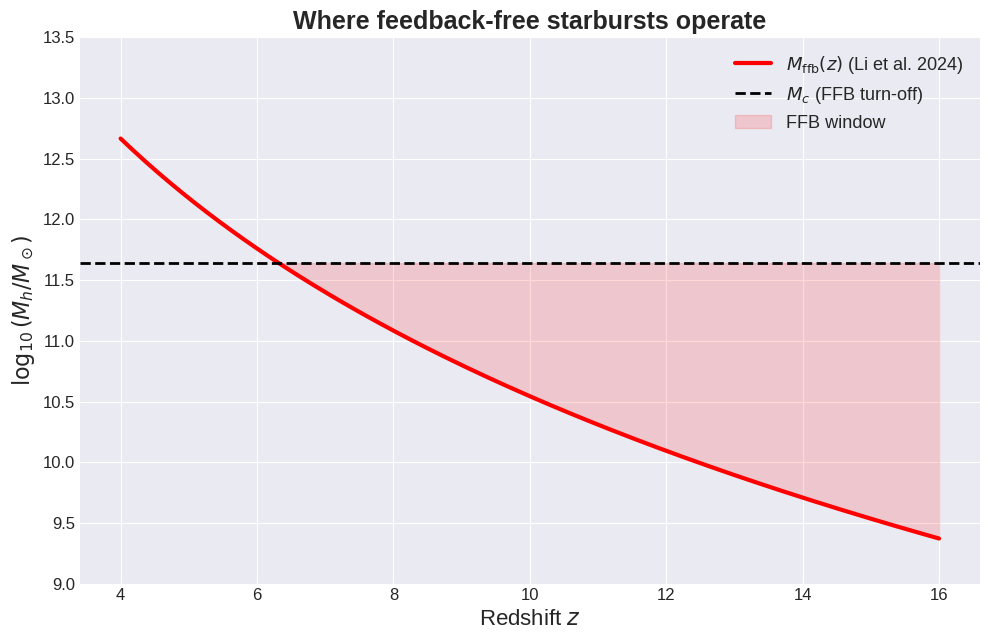

   z  log M_ffb  max f_ffb  at log Mh
-------------------------------------
   5      12.18      0.021      11.91
   6      11.76      0.161      11.70
   7      11.40      0.475      11.52
   8      11.08      0.748      11.36
  10      10.54      0.950      11.09
  12      10.09      0.989      10.87
  14       9.71      0.997      10.67


In [2]:
z_grid = np.linspace(4, 16, 200)
logM_ffb = [np.log10(UVHMRModel_FFB(z=z).M_ffb) for z in z_grid]
logMc = np.log10(UVHMRModel_FFB(z=10.0).Mc)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(z_grid, logM_ffb, 'r-', lw=3, label=r'$M_{\rm ffb}(z)$ (Li et al. 2024)')
ax.axhline(logMc, color='k', ls='--', lw=2, label=r'$M_c$ (FFB turn-off)')
ax.fill_between(z_grid, logM_ffb, logMc, where=np.array(logM_ffb) < logMc,
                color='r', alpha=0.15, label='FFB window')
ax.set_xlabel('Redshift $z$', fontsize=16)
ax.set_ylabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
ax.set_title('Where feedback-free starbursts operate', fontsize=18, fontweight='bold')
ax.set_ylim(9, 13.5)
ax.legend(fontsize=13)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

Mh = np.logspace(9, 14, 501)
print(f"{'z':>4} {'log M_ffb':>10} {'max f_ffb':>10} {'at log Mh':>10}")
print("-" * 37)
for z in [5, 6, 7, 8, 10, 12, 14]:
    m = UVHMRModel_FFB(z=z)
    f = m.ffb_fraction(Mh)
    print(f"{z:>4} {np.log10(m.M_ffb):10.2f} {f.max():10.3f} {np.log10(Mh[f.argmax()]):10.2f}")

## Part 2: FFB fraction and star formation efficiency

`ffb_fraction(Mh)` and `star_formation_efficiency(Mh)` are defined on `HMRModel_FFB`, the base class of every FFB model. The left panel shows the FFB fraction at several redshifts. At $z=6$ the window has almost closed, so $f_{\rm ffb}$ never gets far above zero. The right panel shows the resulting efficiency at $z=10$ for several values of `eps_max_ffb`.

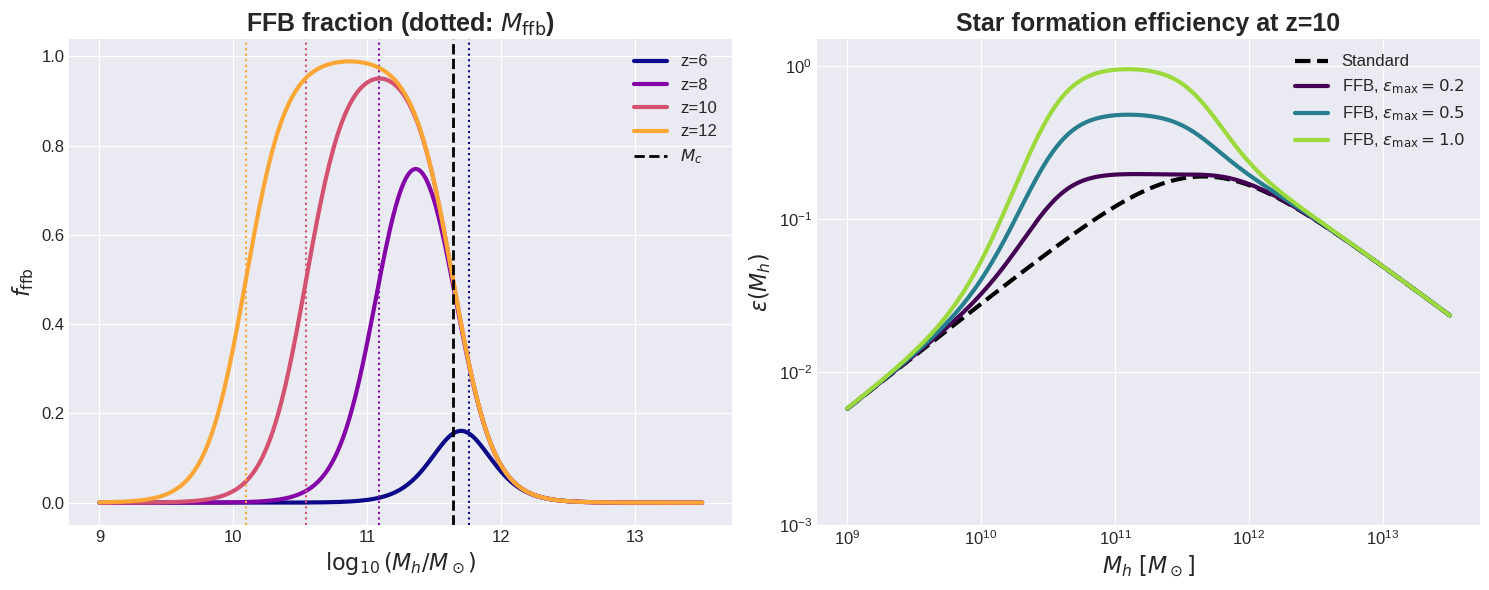

In [3]:
Mh = np.logspace(9, 13.5, 300)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for z, c in zip([6, 8, 10, 12], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    m = UVHMRModel_FFB(z=z)
    axes[0].plot(np.log10(Mh), m.ffb_fraction(Mh), color=c, lw=3, label=f'z={z}')
    axes[0].axvline(np.log10(m.M_ffb), color=c, ls=':', lw=1.5)
axes[0].axvline(np.log10(m.Mc), color='k', ls='--', lw=2, label=r'$M_c$')
axes[0].set_ylabel(r'$f_{\rm ffb}$', fontsize=16)
axes[0].set_title(r'FFB fraction (dotted: $M_{\rm ffb}$)', fontsize=18, fontweight='bold')

std = UVHMRModel(z=10.0)
axes[1].loglog(Mh, std.star_formation_efficiency(Mh), 'k--', lw=3, label='Standard')
for eps_max, c in zip([0.2, 0.5, 1.0], plt.cm.viridis(np.linspace(0, 0.85, 3))):
    m = UVHMRModel_FFB(z=10.0, eps_max_ffb=eps_max)
    axes[1].loglog(Mh, m.star_formation_efficiency(Mh), color=c, lw=3,
                   label=rf'FFB, $\varepsilon_{{\rm max}} = {eps_max}$')
axes[1].set_ylim(1e-3, 1.5)
axes[1].set_ylabel(r'$\varepsilon(M_h)$', fontsize=16)
axes[1].set_title('Star formation efficiency at z=10', fontsize=18, fontweight='bold')

axes[0].set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
axes[1].set_xlabel(r'$M_h\ [M_\odot]$', fontsize=16)
for ax in axes:
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

### Effect of the transition width `ffb_delta`

`ffb_delta` sets how sharply FFBs switch on and off. At $z=10$ the window is about 1.1 dex wide. A wide transition both smooths the edges and lowers the peak FFB fraction, because the two sigmoids overlap.

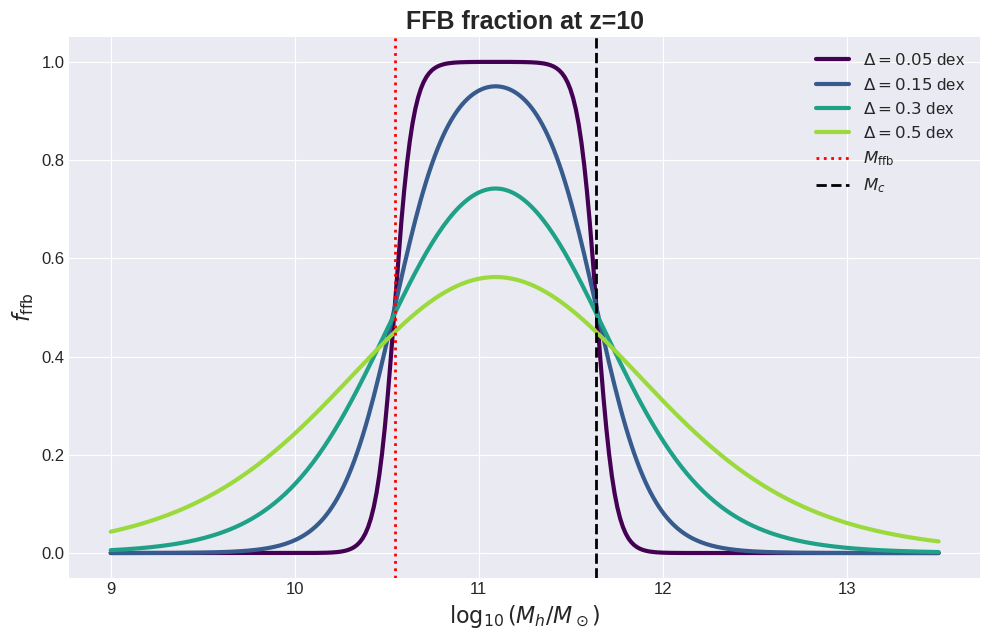

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for delta, c in zip([0.05, 0.15, 0.3, 0.5], plt.cm.viridis(np.linspace(0, 0.85, 4))):
    m = UVHMRModel_FFB(z=10.0, ffb_delta=delta)
    ax.plot(np.log10(Mh), m.ffb_fraction(Mh), color=c, lw=3,
            label=rf'$\Delta = {delta}$ dex')
ax.axvline(np.log10(m.M_ffb), color='r', ls=':', lw=2, label=r'$M_{\rm ffb}$')
ax.axvline(np.log10(m.Mc), color='k', ls='--', lw=2, label=r'$M_c$')
ax.set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$f_{\rm ffb}$', fontsize=16)
ax.set_title('FFB fraction at z=10', fontsize=18, fontweight='bold')
ax.legend(fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

## Part 3: UV and stellar-mass relations with FFBs

`UVHMRModel_FFB` and `SHMRModel_FFB` take every parameter of `UVHMRModel` or `SHMRModel`, plus `ffb_delta` and `eps_max_ffb`. They are built by multiple inheritance, e.g. `class UVHMRModel_FFB(UVHMRModel, HMRModel_FFB)`. The method resolution order places `HMRModel_FFB` just before `HMRModel`, so every method of the parent (`MUV`, `sfr`, `Mstar`, `Mhalo`, ...) automatically uses the FFB efficiency.

In [5]:
print(" -> ".join(cls.__name__ for cls in UVHMRModel_FFB.__mro__))
print()
print("UVHMRModel_FFB parameters:", UVHMRModel_FFB.param_names())
print("SHMRModel_FFB parameters: ", SHMRModel_FFB.param_names())

UVHMRModel_FFB -> UVHMRModel -> HMRModel_FFB -> HMRModel -> ABC -> object

UVHMRModel_FFB parameters: ('z', 'eps0', 'Mc', 'a', 'b', 'add_dust', 'ffb_delta', 'eps_max_ffb')
SHMRModel_FFB parameters:  ('z', 'eps0', 'Mc', 'a', 'b', 'ffb_delta', 'eps_max_ffb')


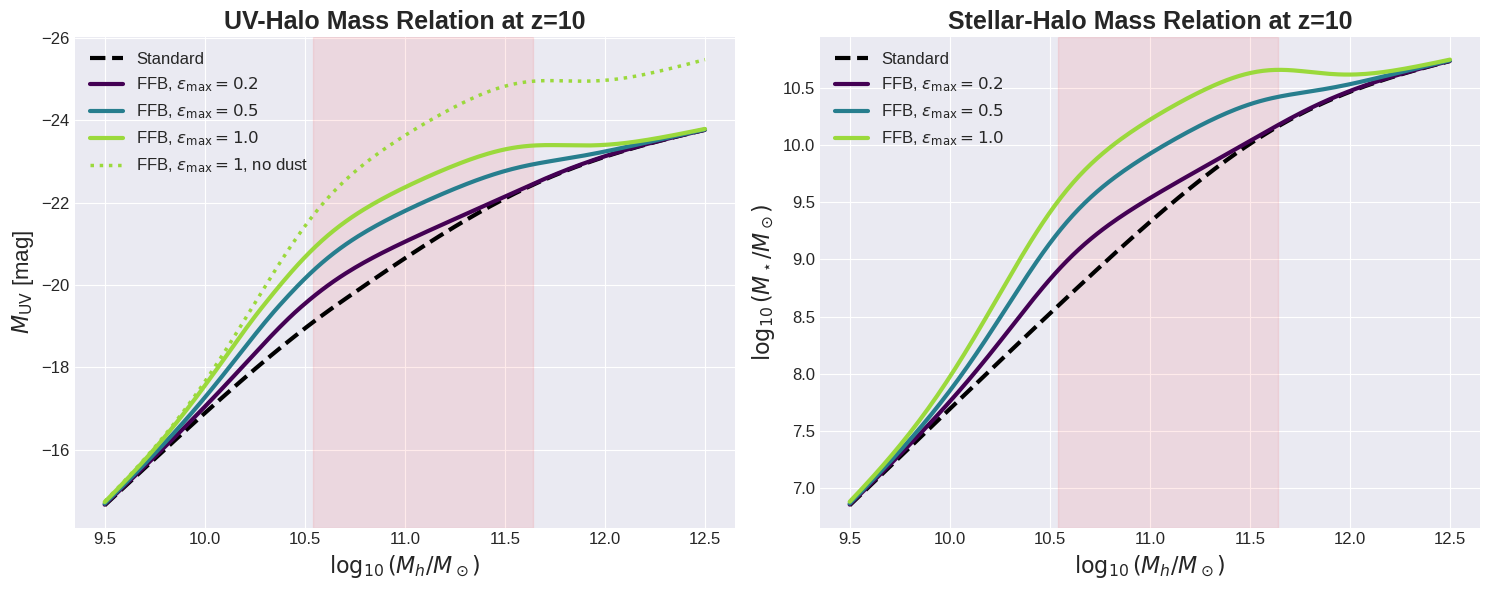

In [6]:
Mh = np.logspace(9.5, 12.5, 200)
z = 10.0

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].plot(np.log10(Mh), UVHMRModel(z=z).MUV(Mh), 'k--', lw=3, label='Standard')
axes[1].plot(np.log10(Mh), np.log10(SHMRModel(z=z).Mstar(Mh)), 'k--', lw=3, label='Standard')
for eps_max, c in zip([0.2, 0.5, 1.0], plt.cm.viridis(np.linspace(0, 0.85, 3))):
    label = rf'FFB, $\varepsilon_{{\rm max}} = {eps_max}$'
    axes[0].plot(np.log10(Mh), UVHMRModel_FFB(z=z, eps_max_ffb=eps_max).MUV(Mh),
                 color=c, lw=3, label=label)
    axes[1].plot(np.log10(Mh), np.log10(SHMRModel_FFB(z=z, eps_max_ffb=eps_max).Mstar(Mh)),
                 color=c, lw=3, label=label)
axes[0].plot(np.log10(Mh), UVHMRModel_FFB(z=z, add_dust=False).MUV(Mh), ':',
             color=c, lw=2.5, label=r'FFB, $\varepsilon_{\rm max} = 1$, no dust')

axes[0].invert_yaxis()
axes[0].set_ylabel(r'$M_{\rm UV}$ [mag]', fontsize=16)
axes[0].set_title('UV-Halo Mass Relation at z=10', fontsize=18, fontweight='bold')
axes[1].set_ylabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
axes[1].set_title('Stellar-Halo Mass Relation at z=10', fontsize=18, fontweight='bold')
for ax in axes:
    m_ffb = UVHMRModel_FFB(z=z)
    ax.axvspan(np.log10(m_ffb.M_ffb), np.log10(m_ffb.Mc), color='r', alpha=0.08)
    ax.set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

Inside the FFB window (shaded), haloes are up to about 2 mag brighter and hold up to an order of magnitude more stars. Outside it, the FFB and standard relations agree.

**Non-monotonic relations.** Just above $M_c$, the efficiency falls from $\varepsilon_{\rm max}$ back to the standard value faster than $M_h$ grows. For large `eps_max_ffb` the relations then briefly turn over. At $z=10$ with `eps_max_ffb = 1`, $M_\star$ drops by about 0.04 dex between $\log M_h \approx 11.65$ and 12.0, and $M_{\rm UV}$ by about 0.01 mag. Over that range, `Mhalo` has no unique inverse, and $\langle N_{\rm cen}\rangle$ for very bright or massive thresholds can dip slightly below 1 (visible in Part 4). The effect is small for these defaults, but keep it in mind when fitting large `eps_max_ffb`.

**Dust.** With `add_dust=True` (the default), FFB galaxies get the same dust attenuation as everything else. Dust grows with luminosity, so it reduces the brightest part of the boost. Li et al. (2024) suggest FFB galaxies may be largely dust-free, so the dotted `add_dust=False` curve gives an upper bound.

The inverse relation still works, because `Mhalo` inverts whatever `property(Mh)` the model defines:

In [7]:
m = UVHMRModel_FFB(z=10.0)
MUV_targets = np.array([-18.0, -20.0, -22.0])
Mh_host = m.Mhalo(MUV_targets)
Mh_host_std = UVHMRModel(z=10.0).Mhalo(MUV_targets)

for muv, mh, mh_std in zip(MUV_targets, Mh_host, Mh_host_std):
    print(f"MUV = {muv:5.1f}  ->  log10 Mh = {np.log10(mh):.2f} (FFB), {np.log10(mh_std):.2f} (standard)")

MUV = -18.0  ->  log10 Mh = 10.07 (FFB), 10.26 (standard)
MUV = -20.0  ->  log10 Mh = 10.38 (FFB), 10.80 (standard)
MUV = -22.0  ->  log10 Mh = 10.85 (FFB), 11.46 (standard)


## Part 4: FFB HOD models

`UVHODModel_FFB` and `MstarHODModel_FFB` add the HOD parameters to the FFB relations. They subclass `UVHODModel` and `MstarHODModel`, so `isinstance` checks, `Observables(model)` dispatch and every observable work unchanged. All parameters can be set at construction:

In [8]:
model = UVHODModel_FFB(
    z=10.0,             # Redshift
    eps0=0.19,          # Standard SFE normalisation
    Mc=10**11.64,       # Characteristic halo mass, also the FFB turn-off [M_sun]
    a=0.69,             # Low-mass slope
    b=0.65,             # High-mass slope
    sigma_UV=0.69,      # Scatter in MUV at fixed Mh [mag]
    Mcut=10**9.57,      # Satellite cutoff mass [M_sun]
    Msat=10**12.65,     # Satellite normalisation mass [M_sun]
    asat=0.85,          # Satellite power-law slope
    ffb_delta=0.15,     # FFB transition width [dex]
    eps_max_ffb=1.0,    # SFE in the FFB phase
)

print(model)
print()
print("isinstance(model, UVHODModel):", isinstance(model, UVHODModel))
print("Parameters:", model.param_names())

UVHODModel_FFB at z=10.0
HMR Parameters:
  eps0 = 0.190
  Mc = 4.37e+11 M_sun
  a = 0.69
  b = 0.65

HOD Parameters:
  sigma_UV = 0.69 mag
  Mcut = 3.72e+09 M_sun
  Msat = 4.47e+12 M_sun
  asat = 0.85

Settings:
  ffb_delta = 0.15
  eps_max_ffb = 1.0
  add_dust = True

isinstance(model, UVHODModel): True
Parameters: ('z', 'eps0', 'Mc', 'a', 'b', 'add_dust', 'ffb_delta', 'eps_max_ffb', 'sigma_UV', 'Mcut', 'Msat', 'asat')


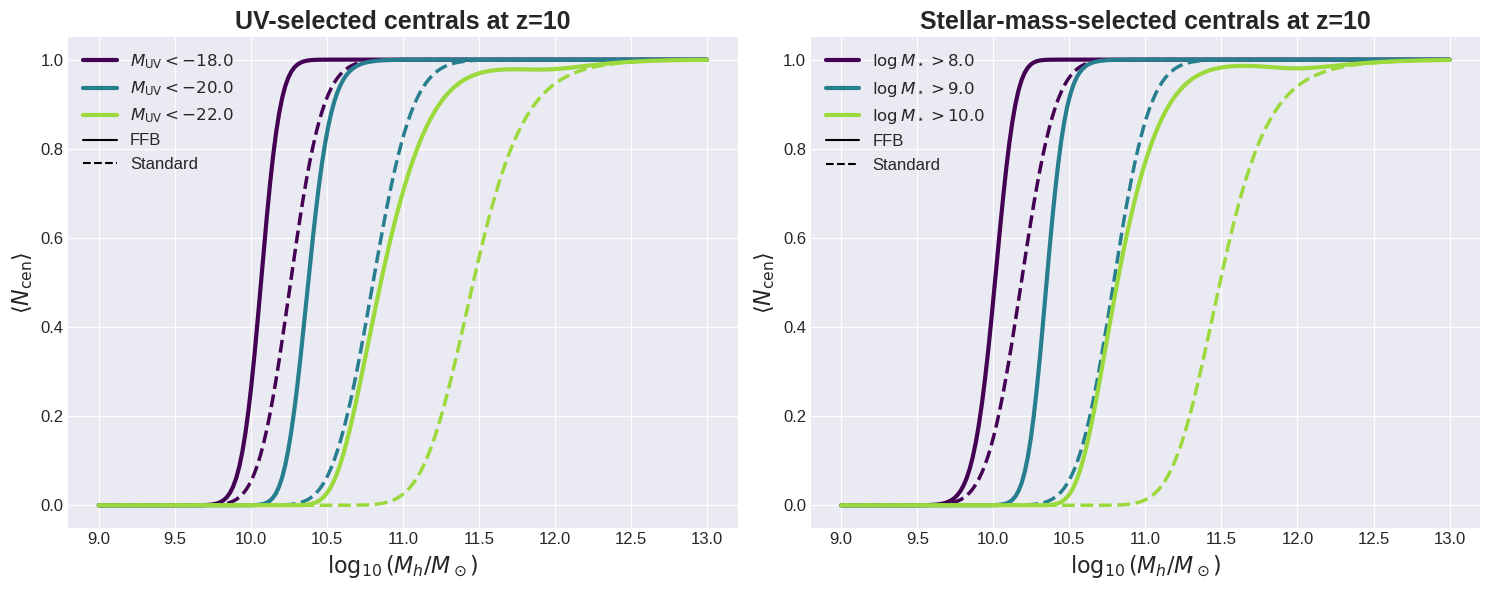

In [9]:
Mh_range = np.logspace(9, 13, 200)
thresholds = [-18.0, -20.0, -22.0]
colors = plt.cm.viridis(np.linspace(0, 0.85, len(thresholds)))
std_model = UVHODModel(z=10.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for thresh, c in zip(thresholds, colors):
    axes[0].plot(np.log10(Mh_range), model.Ncen(Mh_range, thresh), '-', color=c, lw=3,
                 label=rf'$M_{{\rm UV}} < {thresh}$')
    axes[0].plot(np.log10(Mh_range), std_model.Ncen(Mh_range, thresh), '--', color=c, lw=2.5)

mstar_ffb, mstar_std = MstarHODModel_FFB(z=10.0), MstarHODModel(z=10.0)
for thresh, c in zip([8.0, 9.0, 10.0], colors):
    axes[1].plot(np.log10(Mh_range), mstar_ffb.Ncen(Mh_range, thresh), '-', color=c, lw=3,
                 label=rf'$\log M_\star > {thresh}$')
    axes[1].plot(np.log10(Mh_range), mstar_std.Ncen(Mh_range, thresh), '--', color=c, lw=2.5)

for ax, title in zip(axes, ['UV-selected centrals', 'Stellar-mass-selected centrals']):
    ax.plot([], [], 'k-', label='FFB')
    ax.plot([], [], 'k--', label='Standard')
    ax.set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
    ax.set_ylabel(r'$\langle N_{\rm cen} \rangle$', fontsize=16)
    ax.set_title(f'{title} at z=10', fontsize=18, fontweight='bold')
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

FFBs move the central occupation to **lower halo masses**, because a less massive halo is now enough to reach the threshold. The shift grows with the threshold: about 0.2 dex for $M_{\rm UV} < -18$, whose haloes sit mostly below the FFB window, and about 0.6 dex for $M_{\rm UV} < -22$.

## Part 5: UV luminosity and stellar mass functions

`Observables(model)` returns a `UVObservables` for `UVHODModel_FFB` and a `MstarObservables` for `MstarHODModel_FFB`, just as for the standard models.

### The UVLF at z = 10

UVObservables UVObservables


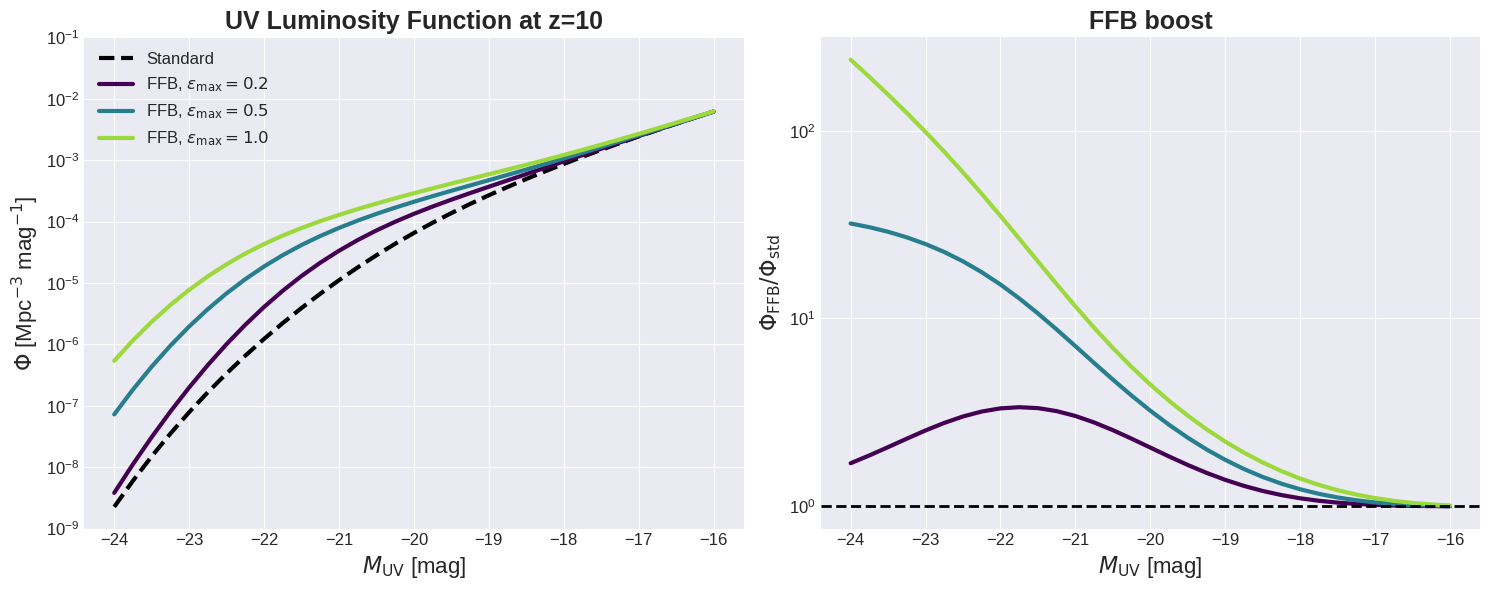

eps_max_ffb now: 1.0


In [10]:
obs_ffb = Observables(UVHODModel_FFB(z=10.0))
obs_std = Observables(UVHODModel(z=10.0))
print(type(obs_ffb).__name__, type(obs_std).__name__)

MUV = np.linspace(-24, -16, 33)
phi_std = obs_std.luminosity_function(MUV)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].semilogy(MUV, phi_std, 'k--', lw=3, label='Standard')
for eps_max, c in zip([0.2, 0.5, 1.0], plt.cm.viridis(np.linspace(0, 0.85, 3))):
    phi = obs_ffb.luminosity_function(MUV, eps_max_ffb=eps_max)
    axes[0].semilogy(MUV, phi, color=c, lw=3, label=rf'FFB, $\varepsilon_{{\rm max}} = {eps_max}$')
    axes[1].semilogy(MUV, phi / phi_std, color=c, lw=3)

axes[0].set_ylim(1e-9, 1e-1)
axes[0].set_ylabel(r'$\Phi$ [Mpc$^{-3}$ mag$^{-1}$]', fontsize=16)
axes[0].set_title('UV Luminosity Function at z=10', fontsize=18, fontweight='bold')
axes[0].legend(fontsize=12)
axes[1].axhline(1, color='k', ls='--', lw=2)
axes[1].set_ylabel(r'$\Phi_{\rm FFB} / \Phi_{\rm std}$', fontsize=16)
axes[1].set_title('FFB boost', fontsize=18, fontweight='bold')
for ax in axes:
    ax.set_xlabel(r'$M_{\rm UV}$ [mag]', fontsize=16)
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# The last override (eps_max_ffb=1.0) persists, so obs_ffb is back at the default.
print("eps_max_ffb now:", obs_ffb.hod_model.eps_max_ffb)

For `eps_max_ffb = 1`, the boost is under 10% faintwards of $M_{\rm UV} \approx -17$ and grows steeply to the bright end: about 4× at $M_{\rm UV} = -20$, 35× at $-22$ and 100× at $-23$. This is how FFBs can explain the abundance of bright galaxies that JWST finds at $z \gtrsim 10$.

For small `eps_max_ffb` the boost is not monotonic. With `eps_max_ffb = 0.2` it peaks at about 3× near $M_{\rm UV} = -22$ and then falls again. The brightest galaxies live in haloes above $M_c$, where FFBs are switched off, and an $\varepsilon_{\rm max}$ close to $\varepsilon_0$ gives too little boost inside the window to move FFB haloes up there.

As for the standard model, integrating the UVLF brightwards of a threshold recovers `number_density`:

In [11]:
thresh = -19.0
MUV_fine = np.linspace(-27.0, thresh, 321)
n_from_lf = np.trapz(obs_ffb.luminosity_function(MUV_fine), MUV_fine)
print(f"n(MUV < {thresh}) from integrating the UVLF: {n_from_lf:.3e} Mpc^-3")
print(f"n(MUV < {thresh}) from number_density():     {obs_ffb.number_density(thresh):.3e} Mpc^-3")

n(MUV < -19.0) from integrating the UVLF: 7.304e-04 Mpc^-3
n(MUV < -19.0) from number_density():     7.303e-04 Mpc^-3


### Redshift evolution

The FFB window opens up as $M_{\rm ffb}$ falls with redshift, so the boost grows strongly with $z$. Here `z` is passed as an inline override; the halo mass function is cached per redshift. The Bouwens et al. (2021) data at $z=6$ and $z=8$ are shown for reference.

> The HOD parameters are held at their $z \sim 5$ defaults at every redshift, which is why neither model matches the data closely. To compare with data properly, evolve the parameters with $z$ (as in Part 9 of `basic_usage.ipynb`) or fit them.

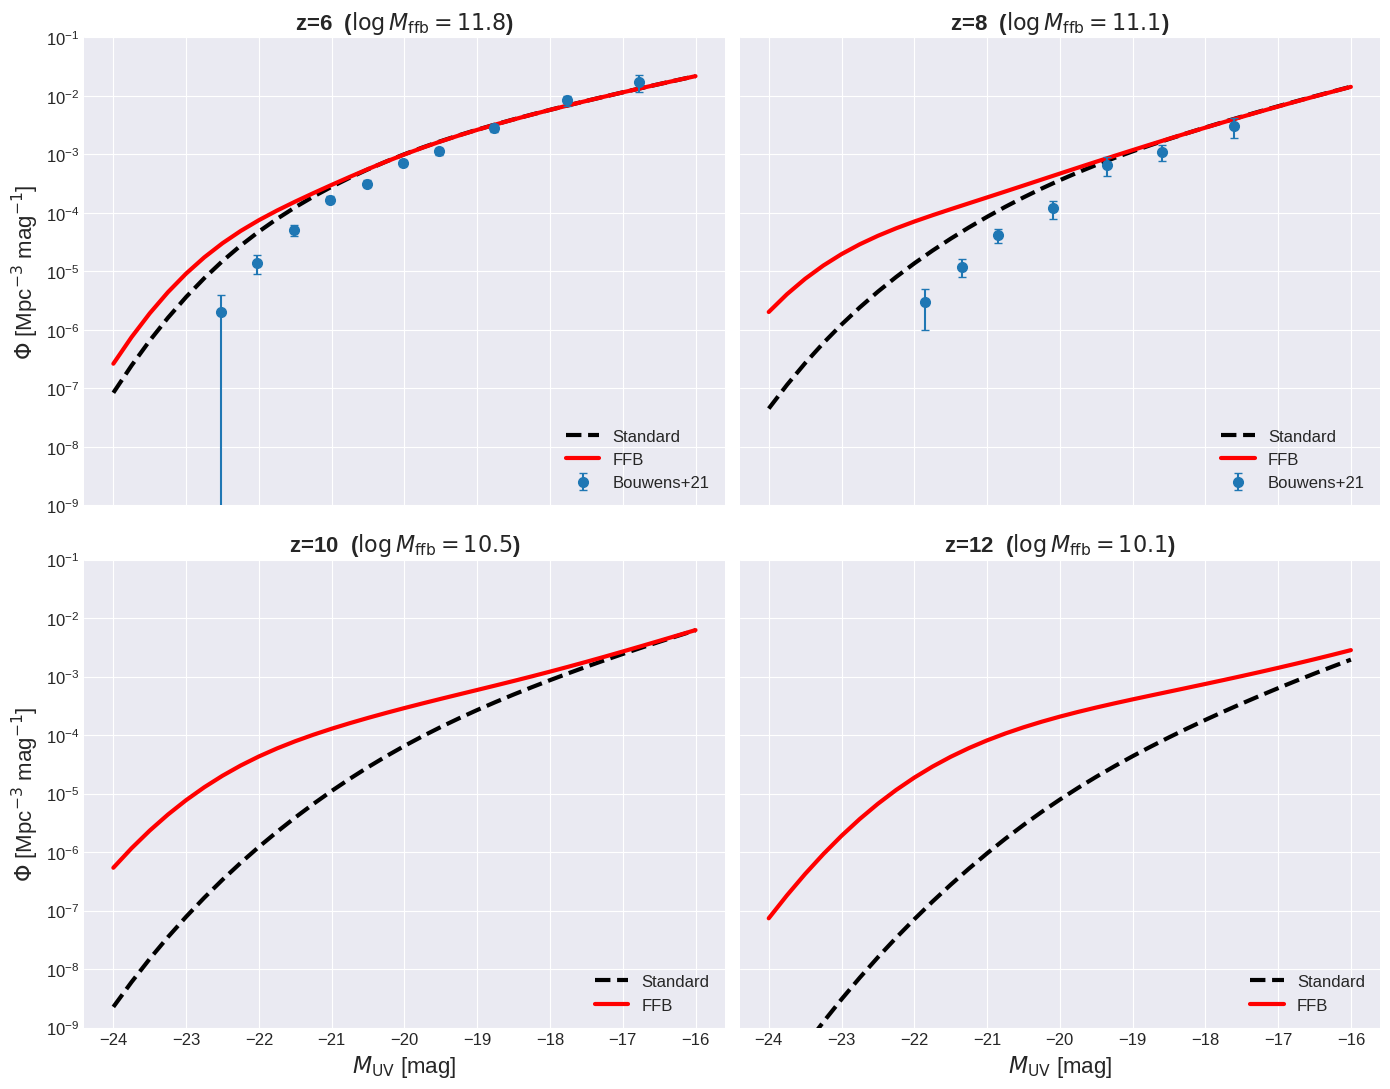

In [12]:
from bouwens21_data import bouwens21

obs_ffb_z = Observables(UVHODModel_FFB(z=10.0))
obs_std_z = Observables(UVHODModel(z=10.0))
MUV = np.linspace(-24, -16, 33)

fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
for ax, z in zip(axes.flat, [6, 8, 10, 12]):
    ax.semilogy(MUV, obs_std_z.luminosity_function(MUV, z=z), 'k--', lw=3, label='Standard')
    ax.semilogy(MUV, obs_ffb_z.luminosity_function(MUV, z=z), 'r-', lw=3, label='FFB')
    key = f'z{z}'
    if key in bouwens21:
        d = bouwens21[key]
        ax.errorbar(d['M_AB'], d['Fi_k'], yerr=d['Fi_k_error'], fmt='o', color='C0',
                    ms=7, capsize=3, label='Bouwens+21')
    m = obs_ffb_z.hod_model
    ax.set_title(rf'z={z}  ($\log M_{{\rm ffb}} = {np.log10(m.M_ffb):.1f}$)',
                 fontsize=16, fontweight='bold')
    ax.set_ylim(1e-9, 1e-1)
    ax.legend(fontsize=12, loc='lower right')
    ax.tick_params(labelsize=12)
for ax in axes[1]:
    ax.set_xlabel(r'$M_{\rm UV}$ [mag]', fontsize=16)
for ax in axes[:, 0]:
    ax.set_ylabel(r'$\Phi$ [Mpc$^{-3}$ mag$^{-1}$]', fontsize=16)
plt.tight_layout()
plt.show()

### The stellar mass function

`MstarHODModel_FFB` works the same way through `stellar_mass_function`. FFBs boost the high-mass end of the SMF.

MstarObservables


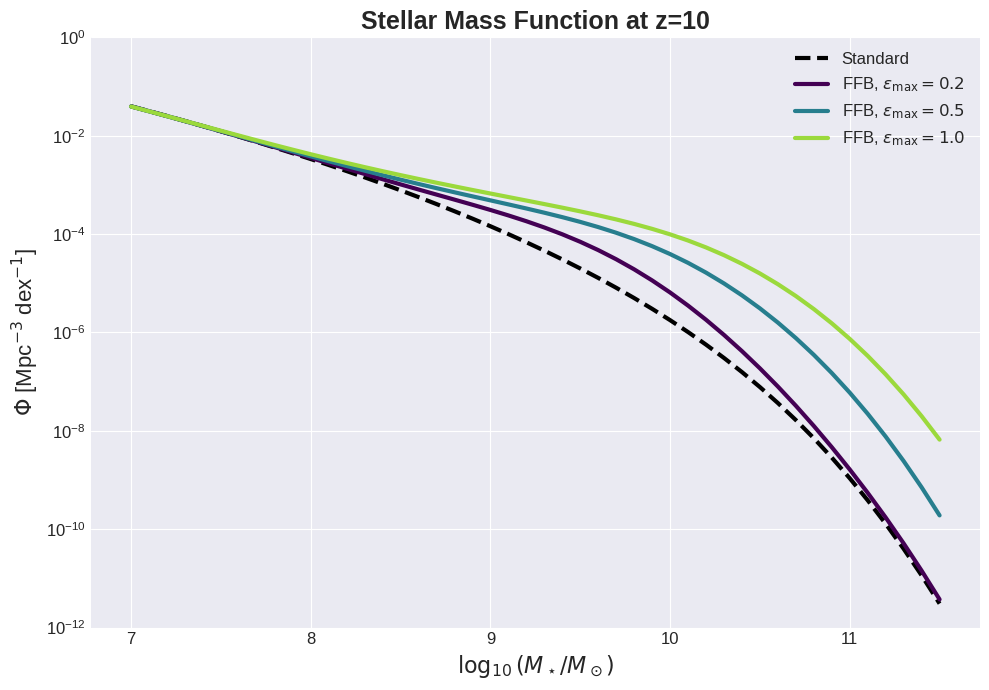

In [13]:
obs_mstar_ffb = Observables(MstarHODModel_FFB(z=10.0))
obs_mstar_std = Observables(MstarHODModel(z=10.0))
print(type(obs_mstar_ffb).__name__)

logM = np.linspace(7.0, 11.5, 46)
fig, ax = plt.subplots(figsize=(10, 7))
ax.semilogy(logM, obs_mstar_std.stellar_mass_function(logM), 'k--', lw=3, label='Standard')
for eps_max, c in zip([0.2, 0.5, 1.0], plt.cm.viridis(np.linspace(0, 0.85, 3))):
    ax.semilogy(logM, obs_mstar_ffb.stellar_mass_function(logM, eps_max_ffb=eps_max),
                color=c, lw=3, label=rf'FFB, $\varepsilon_{{\rm max}} = {eps_max}$')
ax.set_ylim(1e-12, 1)
ax.set_xlabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$\Phi$ [Mpc$^{-3}$ dex$^{-1}$]', fontsize=16)
ax.set_title('Stellar Mass Function at z=10', fontsize=18, fontweight='bold')
ax.legend(fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

## Part 6: Galaxy bias and host halo masses

With FFBs, a galaxy of given luminosity lives in a **lighter halo**. Lighter haloes are less biased, so FFB galaxies cluster more weakly than the standard model predicts at the same luminosity. Clustering can therefore distinguish an efficiency boost from simply having more massive haloes.

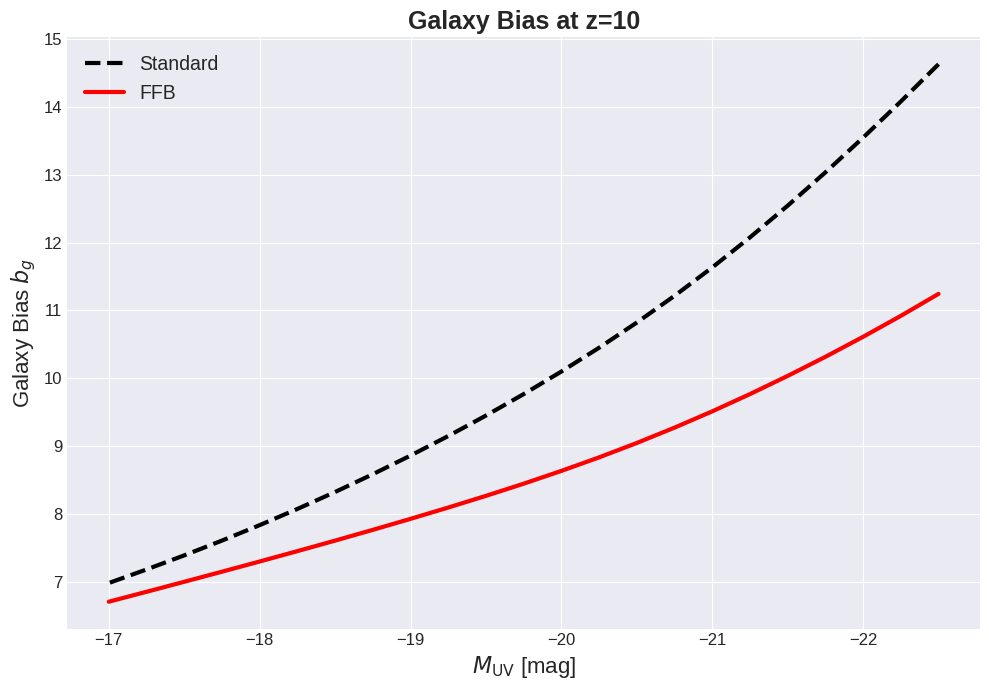

In [14]:
MUV_b = np.linspace(-22.5, -17, 23)

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(MUV_b, obs_std.galaxy_bias(MUV_b), 'k--', lw=3, label='Standard')
ax.plot(MUV_b, obs_ffb.galaxy_bias(MUV_b), 'r-', lw=3, label='FFB')
ax.invert_xaxis()
ax.set_xlabel(r'$M_{\rm UV}$ [mag]', fontsize=16)
ax.set_ylabel('Galaxy Bias $b_g$', fontsize=16)
ax.set_title('Galaxy Bias at z=10', fontsize=18, fontweight='bold')
ax.legend(fontsize=14)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [15]:
print(f"{'':>10} {'n [Mpc^-3]':>23} {'<log Mh>':>15} {'<b>':>13}")
print(f"{'threshold':>10} {'FFB':>11} {'std':>11} {'FFB':>7} {'std':>7} {'FFB':>6} {'std':>6}")
print("-" * 64)
for thresh in [-18.0, -19.0, -20.0, -21.0, -22.0]:
    row = [f"{'< ' + str(thresh):>10}"]
    row += [f"{o.number_density(thresh):11.3e}" for o in (obs_ffb, obs_std)]
    row += [f"{o.mean_halo_mass(thresh):7.2f}" for o in (obs_ffb, obs_std)]
    row += [f"{o.mean_bias(thresh):6.2f}" for o in (obs_ffb, obs_std)]
    print(" ".join(row))

                        n [Mpc^-3]        <log Mh>           <b>
 threshold         FFB         std     FFB     std    FFB    std
----------------------------------------------------------------
   < -18.0   1.591e-03   7.012e-04   10.25   10.36   8.11   8.60
   < -19.0   7.303e-04   1.836e-04   10.38   10.56   8.74   9.63
   < -20.0   3.065e-04   3.664e-05   10.52   10.76   9.43  10.88
   < -21.0   1.059e-04   5.101e-06   10.66   10.98  10.26  12.43
   < -22.0   2.501e-05   4.616e-07   10.81   11.20  11.25  14.31


## Part 7: Parameter exploration

`ffb_delta` and `eps_max_ffb` are ordinary parameters. They appear in `param_names()`, can be passed to `update_parameters`, and can be used as **inline overrides** on any observable method. As with every other parameter, an inline override **persists** on the model afterwards. This is the pattern to use inside an MCMC loop.

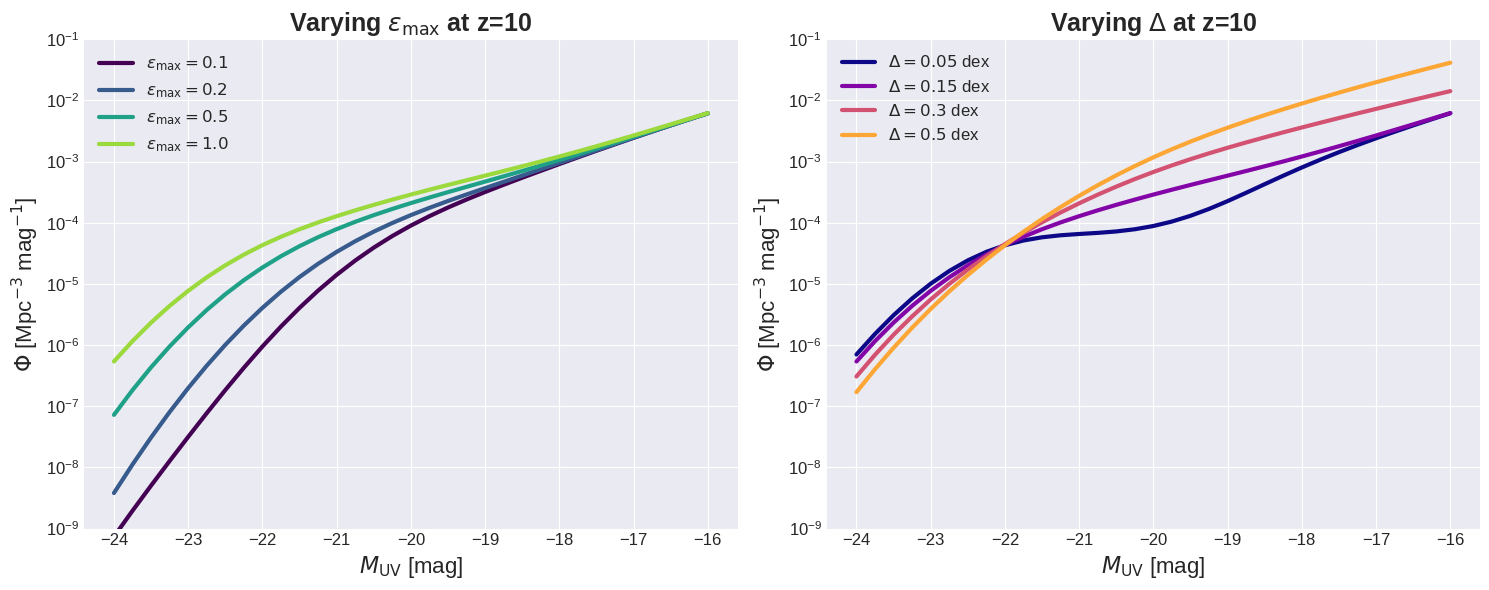

In [16]:
obs_var = Observables(UVHODModel_FFB(z=10.0))
MUV = np.linspace(-24, -16, 33)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for eps_max, c in zip([0.1, 0.2, 0.5, 1.0], plt.cm.viridis(np.linspace(0, 0.85, 4))):
    axes[0].semilogy(MUV, obs_var.luminosity_function(MUV, eps_max_ffb=eps_max),
                     color=c, lw=3, label=rf'$\varepsilon_{{\rm max}} = {eps_max}$')
obs_var.hod_model.update_parameters(eps_max_ffb=1.0)    # restore

for delta, c in zip([0.05, 0.15, 0.3, 0.5], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    axes[1].semilogy(MUV, obs_var.luminosity_function(MUV, ffb_delta=delta),
                     color=c, lw=3, label=rf'$\Delta = {delta}$ dex')
obs_var.hod_model.update_parameters(ffb_delta=0.15)     # restore

for ax, title in zip(axes, [r'Varying $\varepsilon_{\rm max}$', r'Varying $\Delta$']):
    ax.set_xlabel(r'$M_{\rm UV}$ [mag]', fontsize=16)
    ax.set_ylabel(r'$\Phi$ [Mpc$^{-3}$ mag$^{-1}$]', fontsize=16)
    ax.set_title(f'{title} at z=10', fontsize=18, fontweight='bold')
    ax.set_ylim(1e-9, 1e-1)
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [17]:
# MCMC-style loop: FFB and standard parameters together
samples = [(0.15, 0.3, 0.1), (0.19, 0.6, 0.15), (0.25, 1.0, 0.3)]   # (eps0, eps_max_ffb, ffb_delta)
for eps0, eps_max, delta in samples:
    phi = obs_var.luminosity_function(np.array([-21.0]), eps0=eps0,
                                      eps_max_ffb=eps_max, ffb_delta=delta)[0]
    n = obs_var.number_density(-19.0)          # uses the parameters just set
    print(f"eps0={eps0:.2f}, eps_max_ffb={eps_max:.1f}, ffb_delta={delta:.2f}:  "
          f"Phi(-21) = {phi:.2e} Mpc^-3 mag^-1,  n(<-19) = {n:.2e} Mpc^-3")

# Standard models don't know about FFB parameters, and say so
try:
    obs_std.luminosity_function(MUV, eps_max_ffb=0.5)
except TypeError as err:
    print("\nTypeError:", err)

eps0=0.15, eps_max_ffb=0.3, ffb_delta=0.10:  Phi(-21) = 4.65e-05 Mpc^-3 mag^-1,  n(<-19) = 2.82e-04 Mpc^-3
eps0=0.19, eps_max_ffb=0.6, ffb_delta=0.15:  Phi(-21) = 9.05e-05 Mpc^-3 mag^-1,  n(<-19) = 5.64e-04 Mpc^-3
eps0=0.25, eps_max_ffb=1.0, ffb_delta=0.30:  Phi(-21) = 2.16e-04 Mpc^-3 mag^-1,  n(<-19) = 1.74e-03 Mpc^-3

TypeError: unrecognised parameter(s) ['eps_max_ffb']; expected any of ['Mc', 'Mcut', 'Msat', 'a', 'add_dust', 'asat', 'b', 'eps0', 'sigma_UV', 'z']


> **Fitting.** The `halogal.inference` module currently always builds a standard `HODModel`, so it cannot yet fit `eps_max_ffb` or `ffb_delta`. For now, use the inline-override pattern above inside your own likelihood.

## Part 8: Angular clustering (optional, requires `halomod`)

The correlation-function interface is the same as for standard models: `initialize_correlation_model(...)` builds the halomod model once (slow), and `update_correlation_model(...)` recomputes quickly afterwards.

The halomod wrapper rebuilds its own HOD model from a dictionary of parameters, so an FFB model needs an FFB-aware wrapper. `Observables` picks the right one for you: `HalomodUVHOD_FFB` or `HalomodMstarHOD_FFB` for FFB models, and `HalomodUVHOD` or `HalomodMstarHOD` otherwise. `eps_max_ffb` and `ffb_delta` can then be updated like any other parameter.

Remember that once a correlation model exists, the other observables on that `Observables` object use halomod's HMF instead of Colossus's. Fresh objects are used here so the earlier parts are unaffected.

In [18]:
obs_cf_ffb = Observables(UVHODModel_FFB(z=10.0))
obs_cf_std = Observables(UVHODModel(z=10.0))
print("FFB wrapper:     ", obs_cf_ffb._halomod_wrapper_class().__name__)
print("Standard wrapper:", obs_cf_std._halomod_wrapper_class().__name__)

# Threshold sample MUV < -19 (slow: builds the halomod models)
res_ffb = obs_cf_ffb.initialize_correlation_model(MUV_thresh1=-19.0, correlation_type='angular')
res_std = obs_cf_std.initialize_correlation_model(MUV_thresh1=-19.0, correlation_type='angular')
print(f"theta: {res_ffb['separation'].min():.1f} - {res_ffb['separation'].max():.0f} arcsec")

FFB wrapper:      HalomodUVHOD_FFB
Standard wrapper: HalomodUVHOD


/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/halomod/integrate_corr.py:567: UserWarning: Filter function p(x) did not integrate to 1 (0.9544997333075784). Tentatively re-normalising.
  p1 = _check_p(p1, z if p_of_z else x)
/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/hmf/mass_function/hmf.py:409: UserWarning: Nonlinear mass outside mass range
  warnings.warn("Nonlinear mass outside mass range")


/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/hmf/_internals/_cache.py:115: UserWarning: Using halofit for tracer stats is only valid up to quasi-linear scales k<~1 (h/Mpc).
  value = f(self)


/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/halomod/integrate_corr.py:567: UserWarning: Filter function p(x) did not integrate to 1 (0.9544997333075784). Tentatively re-normalising.
  p1 = _check_p(p1, z if p_of_z else x)
/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/hmf/mass_function/hmf.py:409: UserWarning: Nonlinear mass outside mass range
  warnings.warn("Nonlinear mass outside mass range")


theta: 1.0 - 7200 arcsec


eps_max_ffb=0.2:  w(100") = 0.115,  n(<-19) = 3.02e-04 Mpc^-3


eps_max_ffb=0.5:  w(100") = 0.107,  n(<-19) = 4.77e-04 Mpc^-3


eps_max_ffb=1.0:  w(100") = 0.101,  n(<-19) = 6.79e-04 Mpc^-3
standard:         w(100") = 0.123,  n(<-19) = 1.69e-04 Mpc^-3


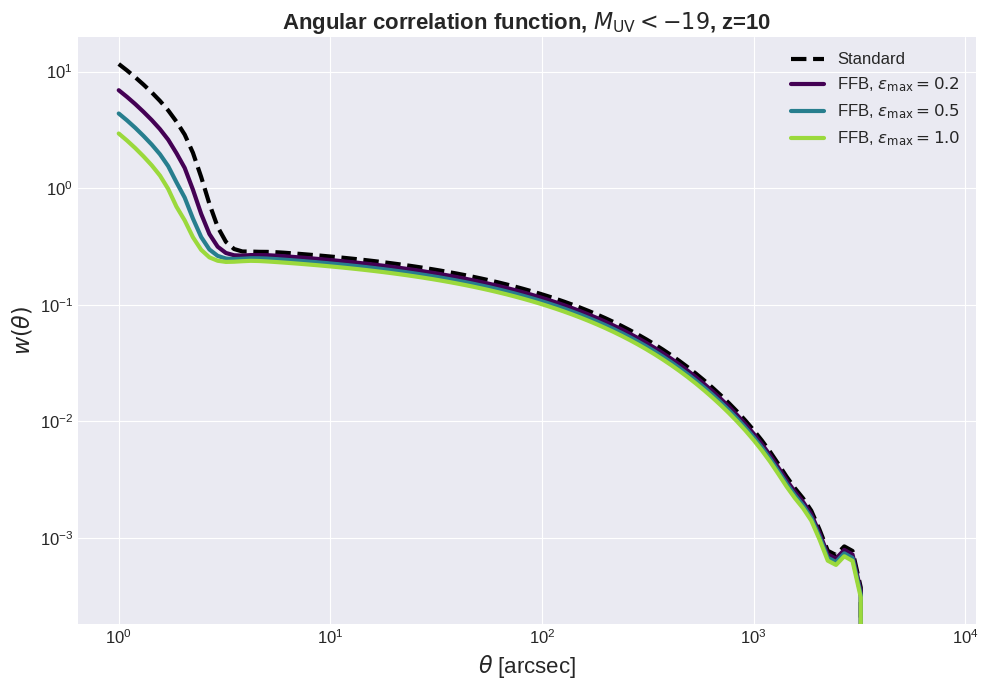

In [19]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.loglog(res_std['separation'], res_std['correlation'], 'k--', lw=3, label='Standard')

for eps_max, c in zip([0.2, 0.5, 1.0], plt.cm.viridis(np.linspace(0, 0.85, 3))):
    res = obs_cf_ffb.update_correlation_model(eps_max_ffb=eps_max)
    ax.loglog(res['separation'], res['correlation'], color=c, lw=3,
              label=rf'FFB, $\varepsilon_{{\rm max}} = {eps_max}$')
    w100 = np.interp(100.0, res['separation'], res['correlation'])
    print(f"eps_max_ffb={eps_max:.1f}:  w(100\") = {w100:.3f},  n(<-19) = "
          f"{obs_cf_ffb.number_density(-19.0):.2e} Mpc^-3")

w100_std = np.interp(100.0, res_std['separation'], res_std['correlation'])
print(f"standard:         w(100\") = {w100_std:.3f},  n(<-19) = "
      f"{obs_cf_std.number_density(-19.0):.2e} Mpc^-3")

ax.set_xlabel(r'$\theta$ [arcsec]', fontsize=16)
ax.set_ylabel(r'$w(\theta)$', fontsize=16)
ax.set_title(r'Angular correlation function, $M_{\rm UV} < -19$, z=10', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

FFB samples cluster more weakly on all scales, as expected from their lighter host haloes. The difference is largest in the one-halo term ($\theta \lesssim 3''$), because fewer of the galaxies are satellites in massive haloes. A stronger FFB boost also raises the number density, so combining $w(\theta)$ with the UVLF helps separate `eps_max_ffb` from the standard parameters.

The number densities printed here come from halomod's HMF, so they differ by a few per cent from the Colossus values in Part 6.

## Summary

| | Standard | With FFBs |
|---|---|---|
| UV relation | `UVHMRModel` | `UVHMRModel_FFB` |
| Stellar-mass relation | `SHMRModel` | `SHMRModel_FFB` |
| UV HOD | `UVHODModel` (alias `HODModel`) | `UVHODModel_FFB` |
| Stellar-mass HOD | `MstarHODModel` | `MstarHODModel_FFB` |
| Extra parameters | none | `ffb_delta` [dex], `eps_max_ffb` |
| Extra methods | | `M_ffb` (property), `ffb_fraction(Mh)` |
| Observables | `UVObservables` / `MstarObservables` | same, via `Observables(model)` |
| halomod wrapper | `HalomodUVHOD` / `HalomodMstarHOD` | `HalomodUVHOD_FFB` / `HalomodMstarHOD_FFB`, chosen automatically |

**Key behaviour:**
- FFBs act only between $M_{\rm ffb}(z)$ and $M_c$. For the default $M_c$ this window closes below $z \approx 6.3$.
- Inside the window, galaxies are brighter and more massive at fixed halo mass. The UVLF and SMF are boosted at the bright and massive end, and bright galaxies sit in lighter, less biased haloes.
- `eps_max_ffb` sets the size of the boost; `ffb_delta` sets how sharply it switches on and off.